# Credit Card Transactions Fraud Detection · 04 Modeling

# Aim, Objective, and Motivation
- **Aim:** <u>find</u> the model that catches the most fraud with the fewest false alarms.
- **Objective:** compare baselines, ensemble models, imbalance strategies and feature sets on the **validation** period,
  then tune the best model with Optuna.
- **Motivation:** every choice is made on validation data only — the test set is used once, in notebook 05.

# Outlines
1. Load datasets
2. Metrics for imbalanced classification
3. Preprocessing
4. Baselines: Dummy, Logistic Regression, Decision Tree
5. Ensemble models: Random Forest, XGBoost, LightGBM
6. Feature ablation: does card history help?
7. Imbalance strategies: none, class weights, undersampling, SMOTE
8. Learning curve: how much data is needed?
9. Hyperparameter tuning with Optuna
10. Benchmark & save the best model
11. Summary

In [1]:
# ---------------------------------------------------------------- Imports
import sys
import json
import time
import warnings
from pathlib import Path

sys.path.append(str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import optuna
import lightgbm as lgb
import xgboost as xgb
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

from src.config import COLORS, MODELS_DIR, ROOT, RANDOM_STATE, TARGET
from src.data import load_processed
from src.evaluate import score, best_f1_threshold, recall_at_precision, plot_pr_roc
from src.features import NUMERIC_FEATURES, CATEGORICAL_FEATURES, FEATURES
from src.plotting import set_style, savefig

# ---------------------------------------------------------------- Global constants
SEED = RANDOM_STATE
N_JOBS = -1
N_TRIALS = 40                          # Optuna trials
EARLY_STOPPING = 100                   # LightGBM rounds without improvement before stopping
UNDERSAMPLE_RATIO = 0.1                # minority : majority after undersampling (1 fraud : 10 legit)
SMOTE_MAJORITY_SAMPLE = 200_000        # legit rows kept before SMOTE (SMOTE on 1M rows is slow)
LEARNING_CURVE_FRACTIONS = [0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0]
MIN_PRECISION = 0.90                   # for the "recall @ 90 % precision" metric
TRANSACTION_ONLY = ["amount", "log_amount", "hour", "day_of_week", "is_night", "age", "is_male",
                    "log_city_pop", "distance_km", "category"]
LGB_BASE = dict(n_estimators=2000, learning_rate=0.05, num_leaves=63, subsample=0.8, subsample_freq=1,
                colsample_bytree=0.8, random_state=SEED, n_jobs=N_JOBS, verbose=-1)
REPORTS_DIR = ROOT / "reports"

set_style()
optuna.logging.set_verbosity(optuna.logging.WARNING)

# [1/11] Load datasets
> **Objective:** <u>load</u> the time-based splits created in notebook 03 and separate features $X$ from target $y$.

In [2]:
train, valid = load_processed("train"), load_processed("valid")
CATS = sorted(train["category"].unique())
for d in (train, valid):
    d["category"] = pd.Categorical(d["category"], categories=CATS)  # identical categories in every split

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]

In [3]:
pd.DataFrame({"rows": [len(X_train), len(X_valid)], "frauds": [y_train.sum(), y_valid.sum()],
              "fraud_rate_%": [y_train.mean() * 100, y_valid.mean() * 100]},
             index=["train", "valid"]).round(3)

,rows,frauds,fraud_rate_%
train,1070966,6250,0.584
valid,225709,1256,0.556


# [2/11] Metrics for imbalanced classification
> **Question:** how do we measure a fraud model when 99.4 % of transactions are legit?

With $TP$ = fraud caught, $FP$ = false alarm, $FN$ = fraud missed:
- **Precision** $= \frac{TP}{TP + FP}$ — of the alerts, how many are real fraud? (cost of investigating)
- **Recall** $= \frac{TP}{TP + FN}$ — of all fraud, how much did we catch? (money saved)
- **F1** $= 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$ — harmonic mean at one threshold
- **PR-AUC (average precision)** $= \sum_n (R_n - R_{n-1}) P_n$ — precision averaged over all recall levels,
  **threshold-free**; a random model scores ≈ the fraud rate (0.0056 here). **Main selection metric.**
- **ROC-AUC** — reported too, but over-optimistic under heavy imbalance (dominated by the huge number of true negatives).
- **Recall @ 90 % precision** — business view: how much fraud we catch if 9 of 10 alerts must be real.

In [4]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_acc = accuracy_score(y_valid, dummy.predict(X_valid))

In [5]:
print(f"'Always legit' model -> accuracy {dummy_acc:.2%}, recall 0 %, PR-AUC {y_valid.mean():.4f}")

'Always legit' model -> accuracy 99.44%, recall 0 %, PR-AUC 0.0056


**Answer:** a model that catches **zero** fraud reaches 99.4 % accuracy → accuracy is useless. We select on **PR-AUC**
and report precision / recall / F1 at the F1-optimal threshold (the cost-optimal threshold is chosen in notebook 05).

# [3/11] Preprocessing
> **Objective:** <u>prepare</u> inputs for each model family.

| Model family | Missing values (first txn of a card) | `category` | Scaling |
|---|---|---|---|
| Linear (Logistic Regression) | median imputation | one-hot | standardise $z = \frac{x - \mu}{\sigma}$ (needed: coefficients are scale-sensitive) |
| sklearn trees (Decision Tree, Random Forest) | median imputation | one-hot | not needed (splits are scale-invariant) |
| Gradient boosting (XGBoost, LightGBM) | native NaN handling | native categorical | not needed |

In [6]:
linear_prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
])
tree_prep = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUMERIC_FEATURES),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES),
])

In [7]:
print("linear input width:", linear_prep.fit_transform(X_train.head(1000)).shape[1], "columns")

linear input width: 32 columns


Helper used for every experiment: fit on train, predict probabilities on valid, store scores.

In [8]:
results, probas, fit_seconds = [], {}, {}


def evaluate(name, model, X_tr=X_train, y_tr=y_train, X_va=X_valid, fit_kwargs=None):
    start = time.time()
    model.fit(X_tr, y_tr, **(fit_kwargs or {}))
    fit_seconds[name] = time.time() - start
    proba = model.predict_proba(X_va)[:, 1]
    thr = best_f1_threshold(y_valid, proba)
    row = score(y_valid, proba, thr, name)
    row["recall@90%prec"] = recall_at_precision(y_valid, proba, MIN_PRECISION)
    row["fit_s"] = fit_seconds[name]
    results.append(row)
    probas[name] = proba
    return model


def results_table(names=None):
    t = pd.DataFrame(results).drop_duplicates("model", keep="last").set_index("model")
    t = t.loc[names] if names else t
    return t.sort_values("pr_auc", ascending=False).round(4)

# [4/11] Baselines
> **Objective:** <u>set</u> the bar every serious model must beat.
> - **Logistic Regression:** $P(y=1 \mid x) = \sigma(w^\top x + b)$, $\sigma(z) = \frac{1}{1 + e^{-z}}$ — linear decision boundary.
>   `class_weight="balanced"` weights each class by $\frac{n}{2\,n_k}$ so one fraud error counts about 170× as much as one legit error.
> - **Decision Tree:** greedy splits minimising Gini impurity $G = 1 - \sum_k p_k^2$ — non-linear but high variance.

In [9]:
evaluate("Logistic Regression", make_pipeline(linear_prep, LogisticRegression(
    max_iter=2000, class_weight="balanced", random_state=SEED)))
evaluate("Decision Tree", make_pipeline(tree_prep, DecisionTreeClassifier(
    max_depth=12, min_samples_leaf=20, class_weight="balanced", random_state=SEED)))

,steps,"[('columntransformer', ...), ('decisiontreeclassifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [10]:
results_table(["Logistic Regression", "Decision Tree"])

,pr_auc,roc_auc,precision,recall,f1,threshold,recall@90%prec,fit_s
model,,,,,,,,
Decision Tree,0.8702,0.9716,0.8619,0.7898,0.8243,0.9965,0.6863,34.4624
Logistic Regression,0.4123,0.9893,0.4648,0.7309,0.5682,0.9722,0.0000,9.1699


**Answer:** both beat random (PR-AUC 0.0056) by a wide margin; the tree is much better than the linear model because
fraud patterns are non-linear (e.g. *large amount* **and** *night* **and** *burst*).

# [5/11] Ensemble models
> **Objective:** <u>reduce</u> the variance of a single tree (bagging) or its bias (boosting).
> - **Random Forest (bagging):** average of $B$ trees, each on a bootstrap sample with random feature subsets:
>   $\hat{p}(x) = \frac{1}{B}\sum_{b=1}^{B} T_b(x)$
> - **Gradient boosting (XGBoost, LightGBM):** trees added sequentially, each fitting the gradient of the log-loss of the
>   current ensemble: $F_m(x) = F_{m-1}(x) + \eta\, h_m(x)$. Early stopping on the validation set picks the number of trees.

In [11]:
evaluate("Random Forest", make_pipeline(tree_prep, RandomForestClassifier(
    n_estimators=300, min_samples_leaf=5, max_features="sqrt", class_weight="balanced_subsample",
    n_jobs=N_JOBS, random_state=SEED)))

evaluate("XGBoost", xgb.XGBClassifier(
    n_estimators=2000, learning_rate=0.05, max_depth=8, subsample=0.8, colsample_bytree=0.8,
    tree_method="hist", enable_categorical=True, eval_metric="aucpr", early_stopping_rounds=EARLY_STOPPING,
    random_state=SEED, n_jobs=N_JOBS),
    fit_kwargs=dict(eval_set=[(X_valid, y_valid)], verbose=False))

lgb_default = evaluate("LightGBM", lgb.LGBMClassifier(**LGB_BASE), fit_kwargs=dict(
    eval_set=[(X_valid, y_valid)], eval_metric="average_precision",
    callbacks=[lgb.early_stopping(EARLY_STOPPING, verbose=False)]))

In [12]:
results_table()

,pr_auc,roc_auc,precision,recall,f1,threshold,recall@90%prec,fit_s
model,,,,,,,,
XGBoost,0.9870,0.9998,0.9785,0.9435,0.9607,0.3513,0.9721,150.5070
LightGBM,0.9819,0.9997,0.9695,0.9371,0.9530,0.3041,0.9626,35.4399
Random Forest,0.9691,0.9984,0.9470,0.9100,0.9281,0.4955,0.9419,277.9137
Decision Tree,0.8702,0.9716,0.8619,0.7898,0.8243,0.9965,0.6863,34.4624
Logistic Regression,0.4123,0.9893,0.4648,0.7309,0.5682,0.9722,0.0000,9.1699


In [13]:
fig = plot_pr_roc({k: probas[k] for k in results_table().index}, y_valid)
savefig(fig, "04_pr_roc_models")
plt.close(fig)

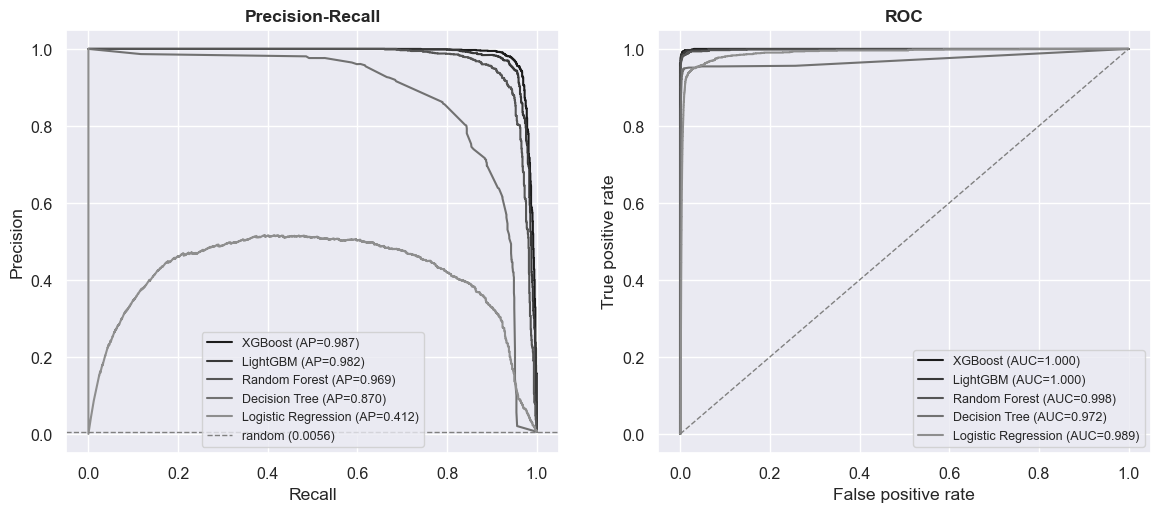

In [14]:
fig

**Answer:** the ensembles are far ahead of the baselines: XGBoost PR-AUC 0.987, LightGBM 0.982, Random Forest 0.969,
against 0.870 for the Decision Tree and 0.412 for Logistic Regression. LightGBM is the fastest ensemble (35 s vs 151 s for
XGBoost and 278 s for Random Forest). ROC-AUC runs from 0.972 to 0.9998 and hardly separates the ensembles
(Logistic Regression still scores 0.989 with PR-AUC 0.41), which is why PR-AUC is the selection metric.

(!) The boosting models use this validation set for early stopping, so their validation scores are slightly optimistic.
The honest number is the test score in notebook 05.

# [6/11] Feature ablation: does card history help?
> **Question:** how much of the performance comes from the card-history features built in notebook 03?
>
> **Method:** same LightGBM, trained with transaction-level features only.

In [15]:
evaluate("LightGBM - transaction features only", lgb.LGBMClassifier(**LGB_BASE),
         X_tr=X_train[TRANSACTION_ONLY], X_va=X_valid[TRANSACTION_ONLY],
         fit_kwargs=dict(eval_set=[(X_valid[TRANSACTION_ONLY], y_valid)], eval_metric="average_precision",
                         callbacks=[lgb.early_stopping(EARLY_STOPPING, verbose=False)]))

,boosting_type,'gbdt'
,num_leaves,63
,max_depth,-1
,learning_rate,0.05
,n_estimators,2000
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [16]:
results_table(["LightGBM", "LightGBM - transaction features only"])

,pr_auc,roc_auc,precision,recall,f1,threshold,recall@90%prec,fit_s
model,,,,,,,,
LightGBM,0.9819,0.9997,0.9695,0.9371,0.9530,0.3041,0.9626,35.4399
LightGBM - transaction features only,0.9168,0.9979,0.9173,0.8217,0.8669,0.4471,0.8320,11.6128


**Answer:** without card history, PR-AUC falls from 0.982 to 0.917 and recall from 0.94 to 0.82 → the **burst behaviour** is a
key signal, and building it without leakage was worth the effort.

# [7/11] Imbalance strategies
> **Question:** should we rebalance the classes, and how?

| Strategy | Idea | Risk |
|---|---|---|
| None | train on the natural 0.58 % fraud rate | the model may under-weight fraud |
| Class weights | weight fraud by $w = \frac{n_{legit}}{n_{fraud}}$ (`scale_pos_weight`) | probabilities no longer calibrated |
| Random undersampling | keep all fraud, sample legit to 1 : 10 | throws away information |
| SMOTE | synthesise fraud: $x_{new} = x_i + \lambda\,(x_{nn} - x_i)$, $\lambda \sim U(0,1)$, $x_{nn}$ = a fraud neighbour | synthetic points can be unrealistic, slow on big data |

All variants use the same LightGBM settings and are scored on the **untouched** validation set (never resample validation data).

In [17]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
rng = np.random.default_rng(SEED)
fraud_idx = np.flatnonzero(y_train.values == 1)
legit_idx = np.flatnonzero(y_train.values == 0)

# random undersampling 1 : 10
under_idx = np.concatenate([fraud_idx, rng.choice(legit_idx, int(len(fraud_idx) / UNDERSAMPLE_RATIO), replace=False)])
X_under, y_under = X_train.iloc[under_idx], y_train.iloc[under_idx]

# SMOTE needs numeric input without NaN -> one-hot category, impute, then oversample fraud to 1 : 10
smote_idx = np.concatenate([fraud_idx, rng.choice(legit_idx, SMOTE_MAJORITY_SAMPLE, replace=False)])
X_sm_in = pd.get_dummies(X_train.iloc[smote_idx], columns=CATEGORICAL_FEATURES, dtype=float)
sm_medians = X_sm_in.median()
X_smote, y_smote = SMOTE(sampling_strategy=UNDERSAMPLE_RATIO, random_state=SEED).fit_resample(
    X_sm_in.fillna(sm_medians), y_train.iloc[smote_idx])
X_valid_dummies = pd.get_dummies(X_valid, columns=CATEGORICAL_FEATURES, dtype=float)[X_sm_in.columns].fillna(sm_medians)

In [18]:
pd.DataFrame({"rows": [len(X_train), len(X_under), len(X_smote)],
              "fraud_share_%": [y_train.mean() * 100, y_under.mean() * 100, y_smote.mean() * 100]},
             index=["original", "undersampled", "SMOTE"]).round(2)

,rows,fraud_share_%
original,1070966,0.58
undersampled,68750,9.09
SMOTE,220000,9.09


In [19]:
es = lambda Xv: dict(eval_set=[(Xv, y_valid)], eval_metric="average_precision",
                     callbacks=[lgb.early_stopping(EARLY_STOPPING, verbose=False)])
results.append({**results_table().loc["LightGBM"].to_dict(), "model": "Imbalance: none"})
probas["Imbalance: none"] = probas["LightGBM"]
evaluate("Imbalance: class weights", lgb.LGBMClassifier(**LGB_BASE, scale_pos_weight=pos_weight), fit_kwargs=es(X_valid))
evaluate("Imbalance: undersampling 1:10", lgb.LGBMClassifier(**LGB_BASE), X_tr=X_under, y_tr=y_under,
         fit_kwargs=es(X_valid))
evaluate("Imbalance: SMOTE 1:10", lgb.LGBMClassifier(**LGB_BASE), X_tr=X_smote, y_tr=y_smote,
         X_va=X_valid_dummies, fit_kwargs=es(X_valid_dummies))
imbalance_names = ["Imbalance: none", "Imbalance: class weights", "Imbalance: undersampling 1:10", "Imbalance: SMOTE 1:10"]

In [20]:
results_table(imbalance_names)

,pr_auc,roc_auc,precision,recall,f1,threshold,recall@90%prec,fit_s
model,,,,,,,,
Imbalance: SMOTE 1:10,0.9839,0.9998,0.9636,0.9482,0.9559,0.8127,0.9682,16.2952
Imbalance: none,0.9819,0.9997,0.9695,0.9371,0.9530,0.3041,0.9626,35.4399
Imbalance: class weights,0.9816,0.9994,0.9721,0.9435,0.9576,0.8137,0.9682,83.3094
Imbalance: undersampling 1:10,0.9803,0.9997,0.9604,0.9260,0.9428,0.9531,0.9626,9.6369


In [21]:
fig = plot_pr_roc({k: probas[k] for k in imbalance_names}, y_valid)
savefig(fig, "04_pr_roc_imbalance")
plt.close(fig)

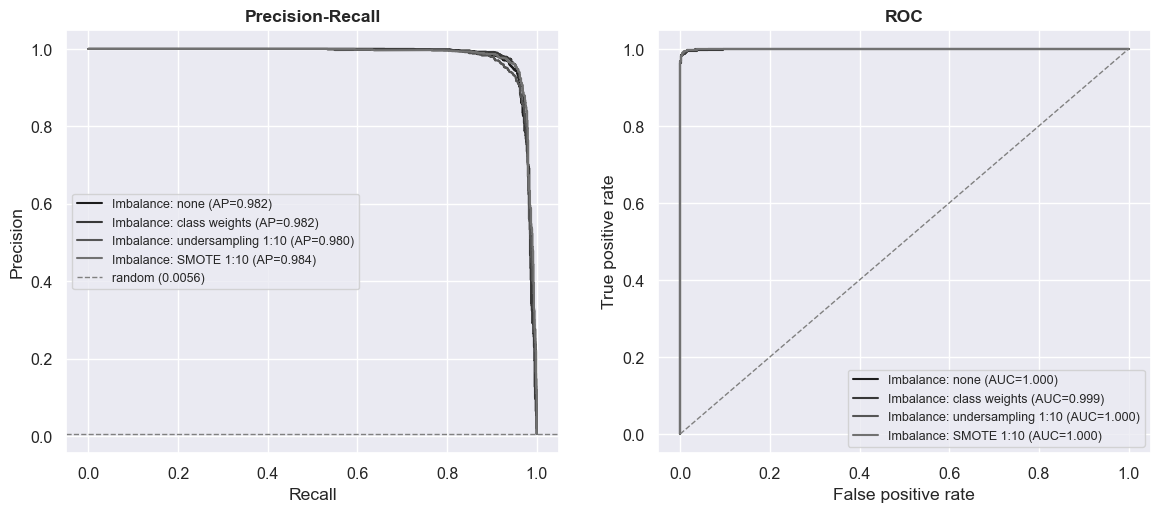

In [22]:
fig

**Answer:** the choice barely matters here: all four land between 0.980 and 0.984. SMOTE is nominally highest (0.9839 vs
0.9819 with no rebalancing), a gap of 0.002 from a single time split, too small to justify synthetic data and the extra
preprocessing. Undersampling is the fastest (10 s vs 35 s) at a small cost (0.9803).
Rebalancing mostly **moves the threshold** (best-F1 threshold 0.30 with no rebalancing, 0.81 with class weights).

**Decision:** keep the natural distribution. It uses all real data and keeps probabilities meaningful; the threshold is
set directly in notebook 05.

# [8/11] Learning curve: how much data is needed?
> **Question:** would more data help, or could we train on less? (the question my first version asked with undersampling)
>
> **Method:** train LightGBM on the most recent fraction $f$ of the training period (recent data is closest to the future)
> and score on validation.

In [23]:
curve = []
for f in LEARNING_CURVE_FRACTIONS:
    n = int(len(X_train) * f)
    Xs, ys = X_train.iloc[-n:], y_train.iloc[-n:]
    m = lgb.LGBMClassifier(**LGB_BASE).fit(Xs, ys, **es(X_valid))
    curve.append({"fraction": f, "rows": n, "frauds": int(ys.sum()),
                  "pr_auc": average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])})
curve = pd.DataFrame(curve)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(curve["rows"], curve["pr_auc"], marker="o", color=COLORS[1])
for _, r in curve.iterrows():
    ax.annotate(f"{int(r.frauds):,} frauds", (r.rows, r.pr_auc), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8)
ax.set(xscale="log", xlabel="training rows (most recent, log scale)", ylabel="valid PR-AUC", title="Learning curve")
savefig(fig, "04_learning_curve")
plt.close(fig)

In [24]:
curve.round(4)

,fraction,rows,frauds,pr_auc
0,0.02,21419,239,0.8126
1,0.05,53548,413,0.8417
2,0.10,107096,774,0.9229
3,0.20,214193,1356,0.9513
4,0.40,428386,2468,0.9677
5,0.70,749676,3945,0.9734
6,1.00,1070966,6250,0.9819


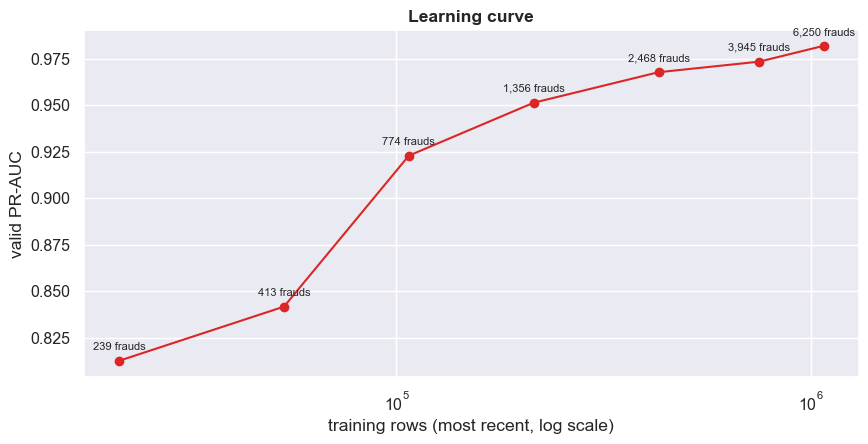

In [25]:
fig

**Answer:** PR-AUC rises steeply up to 20 % of the data (0.813 → 0.951), then keeps improving more slowly
(0.968 at 40 %, 0.973 at 70 %, 0.982 at 100 %). More data still helps a little, so we use all of it.
Each extra fraction also adds *older* data, so this curve mixes data size with data age.

# [9/11] Hyperparameter tuning with Optuna
> **Objective:** <u>search</u> LightGBM hyperparameters to maximise validation PR-AUC.
>
> **Method:** Tree-structured Parzen Estimator (TPE) — models $p(\theta \mid \text{good})$ and $p(\theta \mid \text{bad})$
> and proposes $\theta$ maximising $\frac{p(\theta \mid \text{good})}{p(\theta \mid \text{bad})}$; smarter than grid search
> (used in my first version) for the same budget. Number of trees is set by early stopping inside each trial.

In [26]:
def objective(trial):
    params = dict(
        LGB_BASE,
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=trial.suggest_int("num_leaves", 15, 255, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 300, log=True),
        subsample=trial.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
    )
    m = lgb.LGBMClassifier(**params).fit(X_train, y_train, **es(X_valid))
    trial.set_user_attr("n_estimators", m.best_iteration_)
    return average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])


study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.enqueue_trial({k: LGB_BASE[k] for k in ["learning_rate", "num_leaves", "subsample", "colsample_bytree"]}
                    | {"min_child_samples": 20, "reg_alpha": 1e-3, "reg_lambda": 1e-3})  # start from the default
study.optimize(objective, n_trials=N_TRIALS)
best_params = dict(LGB_BASE, **study.best_params)
best_params["n_estimators"] = study.best_trial.user_attrs["n_estimators"]

trials = study.trials_dataframe(attrs=("number", "value", "params"))
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(trials["number"], trials["value"], "o", color=COLORS[0], alpha=0.6, label="trial")
axes[0].plot(trials["number"], trials["value"].cummax(), color=COLORS[1], label="best so far")
axes[0].set(xlabel="trial", ylabel="valid PR-AUC", title="Optuna optimisation history")
axes[0].legend()
importance = pd.Series(optuna.importance.get_param_importances(study)).sort_values()
axes[1].barh(importance.index, importance.values, color=COLORS[1])
axes[1].set(title="Hyperparameter importance (fANOVA)")
savefig(fig, "04_optuna")
plt.close(fig)

In [27]:
print(f"best valid PR-AUC: {study.best_value:.4f} (default LightGBM: {results_table().loc['LightGBM', 'pr_auc']:.4f})")
best_params

best valid PR-AUC: 0.9863 (default LightGBM: 0.9819)


{'n_estimators': 1109,
 'learning_rate': 0.03632553166214022,
 'num_leaves': 20,
 'subsample': 0.9989791105691248,
 'subsample_freq': 1,
 'colsample_bytree': 0.8559082548800234,
 'random_state': 42,
 'n_jobs': -1,
 'verbose': -1,
 'min_child_samples': 205,
 'reg_alpha': 0.2812113622782828,
 'reg_lambda': 0.287814957440709}

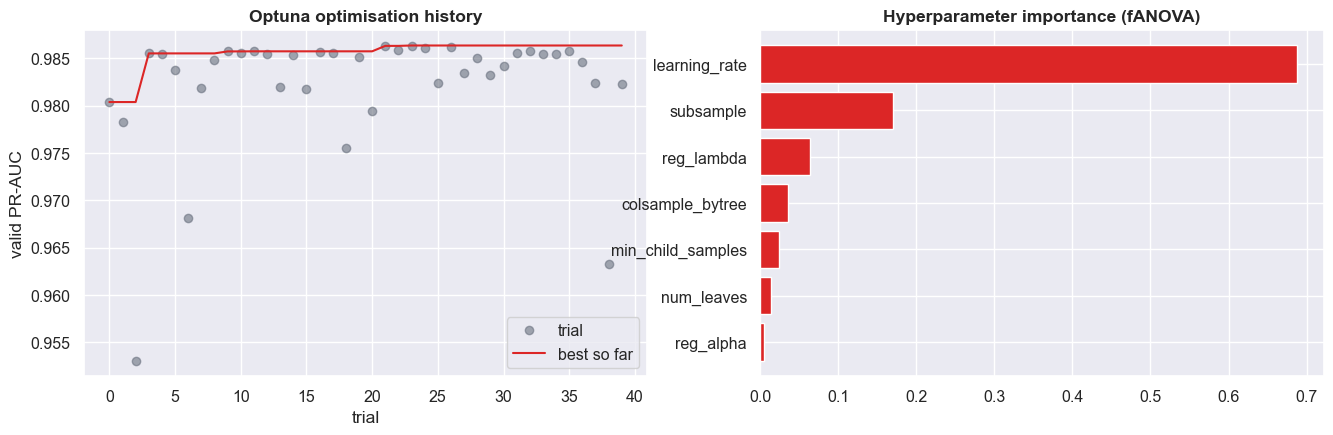

In [28]:
fig

# [10/11] Benchmark & save the best model
> **Objective:** <u>compare</u> every experiment on validation and <u>save</u> the final model.
>
> **Decision:** untuned XGBoost (0.9870) and tuned LightGBM (0.9863) are effectively tied (gap 0.0007). LightGBM is kept
> because it trains about 4× faster, which matters for retraining and for SHAP analysis.

In [29]:
tuned = evaluate("LightGBM (tuned)", lgb.LGBMClassifier(**best_params))
benchmark = results_table()

fig, ax = plt.subplots(figsize=(10, 6))
b = benchmark["pr_auc"].sort_values()
ax.barh(b.index, b.values, color=[COLORS[1] if "tuned" in i else COLORS[0] for i in b.index])
for i, v in enumerate(b.values):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=9)
ax.set(title="Validation PR-AUC of every experiment", xlabel="PR-AUC", xlim=(0, 1.08))
savefig(fig, "04_benchmark")
plt.close(fig)

joblib.dump(tuned, MODELS_DIR / "lgbm_tuned.joblib")
json.dump({"features": FEATURES, "categories": CATS, "params": best_params,
           "valid_pr_auc": float(benchmark.loc["LightGBM (tuned)", "pr_auc"])},
          open(REPORTS_DIR / "best_model.json", "w"), indent=2)
benchmark.to_csv(REPORTS_DIR / "validation_benchmark.csv")

In [30]:
benchmark

,pr_auc,roc_auc,precision,recall,f1,threshold,recall@90%prec,fit_s
model,,,,,,,,
XGBoost,0.9870,0.9998,0.9785,0.9435,0.9607,0.3513,0.9721,150.5070
LightGBM (tuned),0.9863,0.9998,0.9799,0.9339,0.9564,0.3724,0.9705,24.1656
Imbalance: SMOTE 1:10,0.9839,0.9998,0.9636,0.9482,0.9559,0.8127,0.9682,16.2952
Imbalance: none,0.9819,0.9997,0.9695,0.9371,0.9530,0.3041,0.9626,35.4399
LightGBM,0.9819,0.9997,0.9695,0.9371,0.9530,0.3041,0.9626,35.4399
Imbalance: class weights,0.9816,0.9994,0.9721,0.9435,0.9576,0.8137,0.9682,83.3094
Imbalance: undersampling 1:10,0.9803,0.9997,0.9604,0.9260,0.9428,0.9531,0.9626,9.6369
Random Forest,0.9691,0.9984,0.9470,0.9100,0.9281,0.4955,0.9419,277.9137
LightGBM - transaction features only,0.9168,0.9979,0.9173,0.8217,0.8669,0.4471,0.8320,11.6128


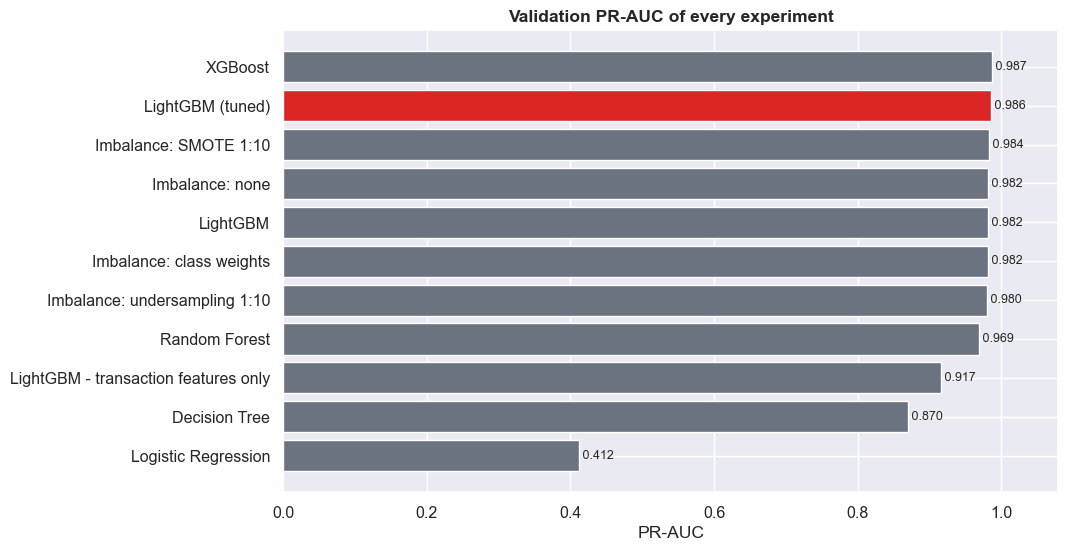

In [31]:
fig

# [11/11] Summary
- **Metric:** PR-AUC (threshold-free, honest under 0.5 % fraud); accuracy is meaningless here.
- **Models:** gradient boosting (0.98–0.99) > Random Forest (0.969) > Decision Tree (0.870) > Logistic Regression (0.412).
- **Feature engineering:** card-history features lift PR-AUC from 0.917 to 0.982.
- **Imbalance:** the four strategies differ by at most 0.004, so we keep the natural distribution and adjust the threshold.
- **Tuning:** Optuna (TPE, 40 trials) improved LightGBM from 0.9819 to 0.9863; the tuned LightGBM is saved to `models/lgbm_tuned.joblib`
  (git-ignored) and its parameters to `reports/best_model.json`.
- Next: notebook 05 refits on train + valid and evaluates **once** on the test period.